In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt
from hnn_core import read_network_configuration, simulate_dipole, JoblibBackend, read_dipole, duecker_ET_model
from hnn_core.dipole import average_dipoles
import numpy as np


pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/'

import sys
n_procs = 3


param_folder  = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/param'
pathgen = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-data/'
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/talk_figs/'
os.makedirs(pathfig, exist_ok=True)

data_url = f'{pathgen}MEG_detection_data/S1_SupraT.txt'
exp_dpl = read_dipole(data_url)
tstop=exp_dpl.times[-1]

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255


plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = '42'


In [2]:

def net_block_ca(net_no_ca):

    sections = ['apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1])
        net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L5_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1])

    sections = ['apical_trunk', 'apical_1', 'apical_tuft']
    for section in sections:
        net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_LVAst_hay2011']['gbar_Ca_LVAst_hay2011'][1])
        net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1] = np.zeros_like(net_no_ca.cell_types['L2_pyramidal']['cell_object'].sections[section].mechs['Ca_HVA_hay2011']['gbar_Ca_HVA_hay2011'][1])


    return net_no_ca

In [3]:
net = read_network_configuration(op.join(param_folder, 'duecker_ET_supra_ERP.json'))

# net = duecker_ET_model()
# for drive in net_optim.external_drives:
#     net.add_evoked_drive(drive, location=net_optim.external_drives[drive]["location"], mu=net_optim.external_drives[drive]["dynamics"]["mu"], sigma=net_optim.external_drives[drive]["dynamics"]["sigma"], numspikes=net_optim.external_drives[drive]["dynamics"]["numspikes"],
#                          weights_ampa = net_optim.external_drives[drive]["weights_ampa"], weights_nmda=net_optim.external_drives[drive]["weights_nmda"], synaptic_delays=net_optim.external_drives[drive]["synaptic_delays"])

In [4]:
scaling_factor=1000
smooth_win = 10
with JoblibBackend(n_jobs=3):
    dpls = simulate_dipole(net, tstop=tstop, bsl_cor="duecker", record_ca='all', record_isec='all', record_vsec='all', n_trials=3)

dpls = [d.scale(scaling_factor).smooth(smooth_win) for d in dpls]
avg_dpl = average_dipoles(dpls)

Joblib will run 3 trial(s) in parallel by distributing trials over 3 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Building the NEURON model
Building the NEURON model
[Done]
[Done]
[Done]
Trial 2: 0.03 ms...
Trial 1: 0.03 ms...
Trial 3: 0.03 ms...
Trial 1: 10.0 ms...
Trial 2: 10.0 ms...
Trial 3: 10.0 ms...
Trial 1: 20.0 ms...
Trial 3: 20.0 ms...
Trial 2: 20.0 ms...
Trial 1: 30.0 ms...
Trial 3: 30.0 ms...
Trial 2: 30.0 ms...
Trial 1: 40.0 ms...
Trial 3: 40.0 ms...
Trial 2: 40.0 ms...
Trial 1: 50.0 ms...
Trial 3: 50.0 ms...
Trial 2: 50.0 ms...
Trial 1: 60.0 ms...
Trial 3: 60.0 

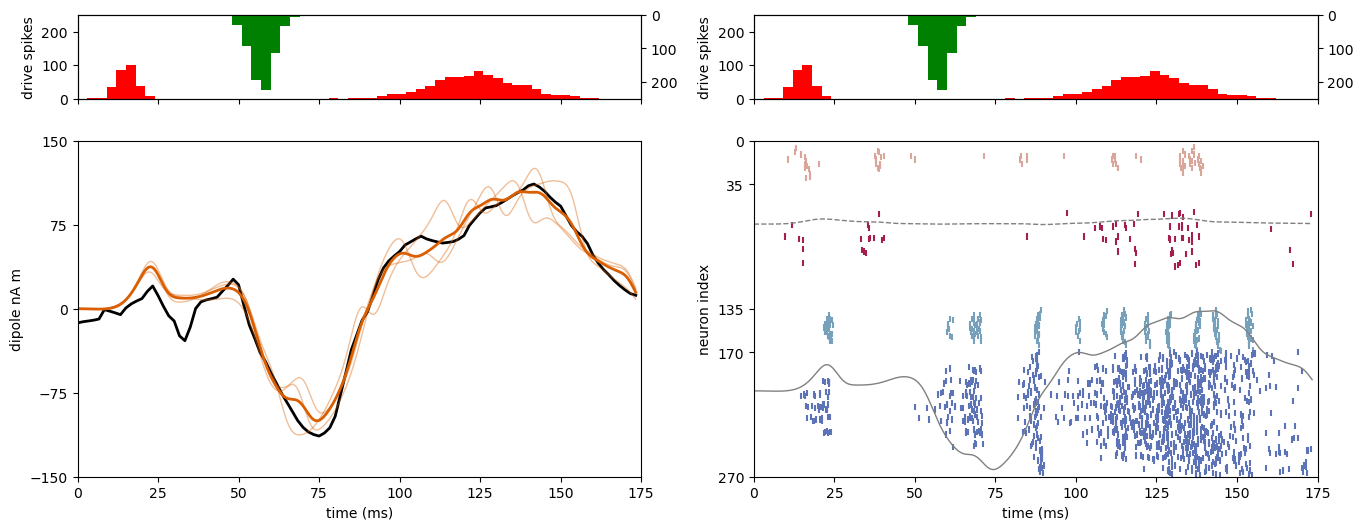

In [5]:
# proximal and distal histogram

fig, ax = plt.subplots(2,2,figsize=(16,6), height_ratios=[0.25, 1], sharex=True)
bins = np.arange(0, tstop, 3)  # histogram bins

spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox1'][0]).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['dist1'][0]).reshape(-1,1)
spike_prox2 = np.array(net.cell_response.spike_times_by_type['prox2'][0]).reshape(-1,1)

for i in range(2):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 250])
    ax[0,i].set_ylabel('drive spikes')
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 250])
    ax1tw.invert_yaxis()

# ERP dipole
ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)
for dpl in dpls:
    ax[1,0].plot(dpl.times,dpl.data['agg'], color=col_lines[1], linewidth=1, alpha=0.4)

ax[1,0].set_ylabel('dipole nA m')
ax[1,0].plot(avg_dpl.times,avg_dpl.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)
#ax[1, 0].text(140, 120, 'RMSE: %.2f' %init_rmse, fontsize=12, color=col_lines[0])
ax[1,0].set_ylim([-150, 150])
ax[1,0].set_yticks([-150, -75, 0, 75, 150])
ax[1,0].set_xlabel('time (ms)')

# Spiking
net.cell_response.plot_spikes_raster(ax=ax[1,1], show=False, overlay_dipoles=True, dpl=dpls, show_legend=False, yticks=[0, 35, 135, 170, 270], xticks=np.arange(0, 176, 25), ylabel='neuron index', xlabel='time (ms)', title='')
ax[1,1].set_ylim([270, 0])


fig.savefig(op.join(pathfig, 'erp_spiking.png'), dpi=600)
fig.savefig(op.join(pathfig, 'erp_spiking.pdf'))

array([<Axes: >, <Axes: >, <Axes: >,
       <Axes: xlabel='time (ms)', ylabel='firing rate (Hz)'>],
      dtype=object)

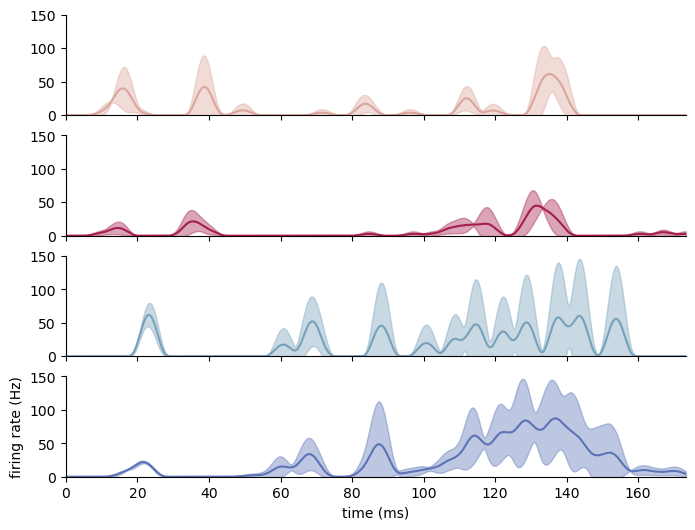

In [6]:
fig, ax = plt.subplots(4,1,figsize=(8,6), sharex=True, sharey=True)
window_length_ms = 10

net.cell_response.plot_firing_rate_time(window_length_ms=window_length_ms, ax=ax, show=False, ylim=[0, 150], show_legend=False)

In [7]:

def calc_FR_rate(net, window_length_ms):
    window_length_samples = window_length_ms * 1/np.diff(net.cell_response.times)[0]
    times = net.cell_response.times
    dt = np.diff(times)[0]
    edges = np.concatenate([times - dt/2, [times[-1] + dt/2]])   # len(times)+1 edges

    taper = np.hanning(int(window_length_samples))
    taper /= taper.sum()
    rates = dict()
    for cell_type in net.cell_response._cell_type_names:
        n_trial = len(net.cell_response.spike_gids)

        rates[cell_type] = np.zeros((n_trial, len(times)))
        if cell_type in net.cell_response.spike_times_by_type:

            for trial in range(n_trial):
                spike_type_time = np.histogram(net.cell_response.spike_times_by_type[cell_type][trial], bins=edges)[0]
                rates[cell_type][trial] = np.convolve(spike_type_time, taper, 'same')/(dt/1000)/len(net.gid_ranges[cell_type])

    return rates

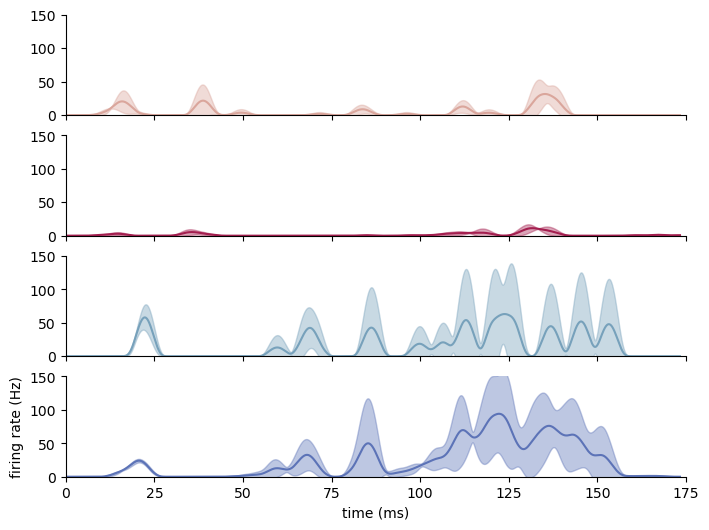

In [8]:
fr_cell_types = calc_FR_rate(net, window_length_ms=window_length_ms)


fig, ax = plt.subplots(4,1,figsize=(8,6), sharex=True, sharey=True)
for c, cell_type in enumerate(net.cell_types):
    ax[c].plot(avg_dpl.times, np.mean(fr_cell_types[cell_type], axis=0), color=net.cell_types[cell_type]['cell_metadata']['color'])
    ax[c].fill_between(avg_dpl.times,
                      np.mean(fr_cell_types[cell_type], axis=0) - np.std(fr_cell_types[cell_type], axis=0),
                      np.mean(fr_cell_types[cell_type], axis=0) + np.std(fr_cell_types[cell_type], axis=0),
                      color=net.cell_types[cell_type]['cell_metadata']['color'], alpha=0.4)
    ax[c].set_xlim((0, 175))
    ax[c].set_xticks(np.arange(0, 176, 25))
    ax[c].set_ylim([0, 150])
    ax[c].spines['top'].set_visible(False)
    ax[c].spines['right'].set_visible(False)

ax[c].set_ylabel('firing rate (Hz)')
ax[c].set_xlabel('time (ms)')



fig.savefig(op.join(pathfig, 'fr_rates.png'), dpi=600)
fig.savefig(op.join(pathfig, 'fr_rates.pdf'))

In [8]:
l23_cols_tone = ['#110308', '#420d20', '#741638', '#a52050']
l5_cols_tone = ['k','#2A3760','#36477B','#425796', '#5C72B7']


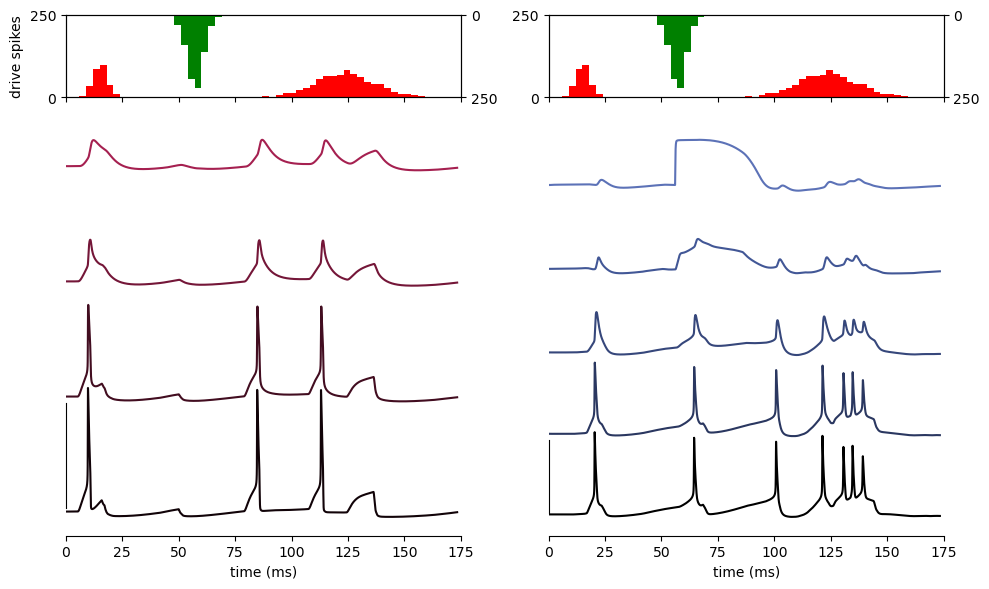

In [9]:
fig, ax = plt.subplots(2,2, figsize=(10,6), height_ratios=[0.2,1], sharex=True)

spike_prox1 = np.array(net.cell_response.spike_times_by_type['prox1'][0]).reshape(-1,1)
spike_dist = np.array(net.cell_response.spike_times_by_type['dist1'][0]).reshape(-1,1)
spike_prox2 = np.array(net.cell_response.spike_times_by_type['prox2'][0]).reshape(-1,1)

ax[0,0].set_ylabel('drive spikes')

for i in range(2):
    ax[0,i].hist(spike_prox1, bins, color='r')
    ax[0,i].set_ylim([0, 250])
    ax[0,i].set_yticks([0, 250])
    ax[0,i].hist(spike_prox2, bins, color='r')

    ax1tw = ax[0,i].twinx()
    ax1tw.hist(spike_dist, bins, color='g')
    ax1tw.set_ylim([0, 250])
    ax1tw.set_yticks([0, 250])
    ax1tw.invert_yaxis()


l23_gids = np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) < 135) & (np.array(net.cell_response.spike_gids[0]) > 35)]
l23_spikes, counts = np.unique(l23_gids, return_counts=True)
gid_oi = int(l23_spikes[np.argmax(counts)])# example that shows distal drive Ca spike

sections = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L2_pyramidal"]['cell_object'].sections[section].L)
prevL = 0
for i, section in enumerate(sections):

    v = np.array(net.cell_response.vsec[0][gid_oi][section])
    ax[1,0].plot(net.cell_response.times, v + i*110, color=l23_cols_tone[i], linewidth=1.5)

# L5 membrane potential

l5_gids = np.array(net.cell_response.spike_gids[0])[(np.array(net.cell_response.spike_gids[0]) >= 170) & (np.array(net.cell_response.spike_gids[0]) < 270)]
l5_spikes, counts = np.unique(l5_gids, return_counts=True)
gid_oi = int(l5_spikes[np.argmax(counts)])      

sections = ['soma','apical_trunk', 'apical_1', 'apical_2', 'apical_tuft']
L = []
for section in sections:
    L.append(net.cell_types["L5_pyramidal"]['cell_object'].sections[section].L)
prevL = 0

for i, section in enumerate(sections):

    v = np.array(net.cell_response.vsec[0][gid_oi][section])
    ax[1,1].plot(net.cell_response.times, v + i*110, color=l5_cols_tone[i], linewidth=1.5)


for i in range(2):
    ax[1,i].spines['left'].set_bounds([-70, 30])
    #ax[1,i].spines['bottom'].set_bounds([0, 50])
    #ax[1,i].set_xticks([])
    ax[1,i].set_yticks([])
    ax[1,i].spines['top'].set_visible(False)
    ax[1,i].spines['right'].set_visible(False)

ax[1,1].set_xlim([0, 175])
ax[1,1].set_xticks(np.arange(0, 176, 25))
ax[1,0].set_xlabel('time (ms)')
ax[1,1].set_xlabel('time (ms)')
fig.tight_layout()
fig.savefig(op.join(pathfig, 'membr_pot_example.png'), dpi=600)
fig.savefig(op.join(pathfig, 'membr_pot_example.pdf'))

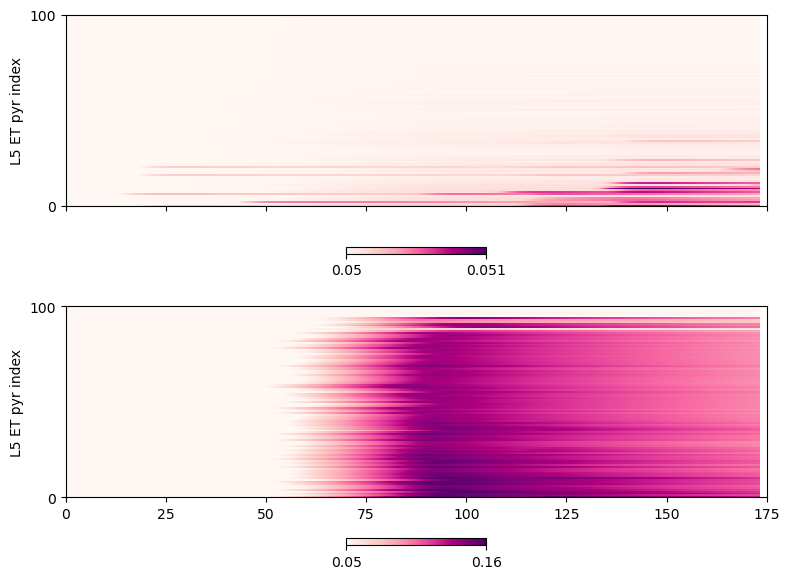

In [10]:
## CALCIUM
# L23 calcium 

fig, ax = plt.subplots(2,1, figsize=(8,6), sharey=True, sharex=True)

l23_tuft_ca = np.zeros((100, len(avg_dpl.times)))

# sort gids based on distance

l23idx = np.argsort(np.sum(np.abs(np.array(net.pos_dict["L2_pyramidal"]) - np.array([4,4,1.3074e+03])), axis=1))
for idx,i in enumerate(l23idx):
    gid = net.gid_ranges["L2_pyramidal"][i]
    l23_tuft_ca[idx] = net.cell_response.ca[0][gid]['apical_tuft']
    idx+=1
    
# convert to micro molar
l23_tuft_ca *=1e3
im = ax[0].pcolormesh(net.cell_response.times, np.arange(100), l23_tuft_ca, shading='auto', cmap='RdPu', rasterized=True)
cb1 = plt.colorbar(im, ax=ax[0], orientation='horizontal', shrink=0.2)
cb1.set_ticks([5e-2, l23_tuft_ca.max()])
cb1.set_ticklabels([f'{5e-2:.1}', f'{l23_tuft_ca.max():.2}'])
ax[0].set_ylim([0, 100])
ax[0].set_yticks([0, 100])
ax[0].set_xlim([0, 175])
# L5 calcium
l5_tuft_ca = np.zeros((100, len(avg_dpl.times)))

l5idx = np.argsort(np.sum(np.abs(np.array(net.pos_dict["L5_pyramidal"]) - np.array([4,4,1.3074e+03])), axis=1))
for idx,i in enumerate(l5idx):
    gid = net.gid_ranges["L5_pyramidal"][i]
    l5_tuft_ca[idx] = net.cell_response.ca[0][gid]['apical_tuft']
    idx+=1

# convert to micromolar
l5_tuft_ca *=1e3
im = ax[1].pcolormesh(net.cell_response.times, np.arange(100), l5_tuft_ca, shading='auto', cmap='RdPu', rasterized=True, vmax=l5_tuft_ca.max())
cb3 = plt.colorbar(im, ax=ax[1], orientation='horizontal', shrink=0.2)
cb3.set_ticks([5e-2, l5_tuft_ca.max()])
cb3.set_ticklabels([f'{5e-2:.1}', f'{l5_tuft_ca.max():.2}'])
ax[1].set_ylim([0, 100])
ax[1].set_yticks([0, 100])
ax[1].set_xlim([0, 175])
ax[1].set_xticks(np.arange(0, 176, 25))
ax[0].set_ylabel('L5 ET pyr index')
ax[1].set_ylabel('L5 ET pyr index')

fig.tight_layout()
fig.savefig(op.join(pathfig, 'erp_tuft_calcium.png'), dpi=600)
fig.savefig(op.join(pathfig, 'erp_tuft_calcium.pdf'))

In [11]:
net_no_ca = read_network_configuration(op.join(param_folder, 'duecker_ET_supra_ERP.json'))
net_no_ca = net_block_ca(net_no_ca)

with JoblibBackend(n_jobs=3):
    dpl_no_ca = simulate_dipole(net_no_ca, tstop=tstop, bsl_cor="duecker", record_ca='all', record_isec='all', record_vsec='all', n_trials=3)

dpl_no_ca = [d.scale(scaling_factor).smooth(smooth_win) for d in dpl_no_ca]
avg_dpl_no_ca = average_dipoles(dpl_no_ca)

Joblib will run 3 trial(s) in parallel by distributing trials over 3 jobs.
Building the NEURON model
Building the NEURON model
Building the NEURON model


KeyboardInterrupt: 

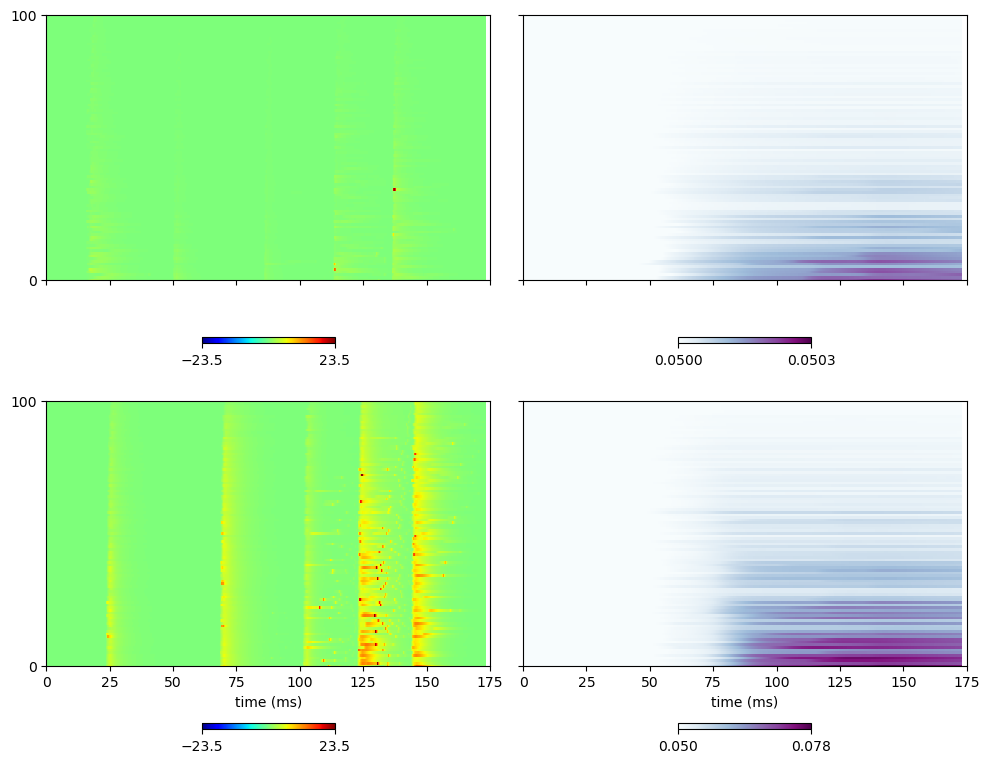

In [ ]:
# NMDA calcium only (VGGC blocked)


fig, ax = plt.subplots(2,2,figsize=(10,8), sharey=True, sharex=True)



## GABAA inhibition at soma
l23_soma_gabaa = np.zeros((100, len(avg_dpl.times)))
for idx, i in enumerate(l23idx):
    gid = net.gid_ranges["L2_pyramidal"][i]
    l23_soma_gabaa[idx] = net.cell_response.isec[0][gid]['soma']['soma_gabaa']
    idx+=1
#fig.tight_layout()
im = ax[0,0].pcolormesh(net.cell_response.times, np.arange(100), l23_soma_gabaa, shading='auto', cmap='jet', rasterized=True, vmin = -l23_soma_gabaa.max(), vmax=l23_soma_gabaa.max())
cb4 = plt.colorbar(im, ax=ax[0,0], orientation='horizontal', shrink=0.3)
cb4.set_ticks([-np.round(l23_soma_gabaa.max(),2), np.round(l23_soma_gabaa.max(),2)])

l5_soma_gabaa = np.zeros((100, len(avg_dpl.times)))
for idx, i in enumerate(l5idx):
    gid = net.gid_ranges["L5_pyramidal"][i]
    l5_soma_gabaa[idx] = net.cell_response.isec[0][gid]['soma']['soma_gabaa']
    idx+=1
#fig.tight_layout()
im = ax[1,0].pcolormesh(net.cell_response.times, np.arange(100), l5_soma_gabaa, shading='auto', cmap='jet', rasterized=True, vmin = -l23_soma_gabaa.max(), vmax=l23_soma_gabaa.max())
cb5 = plt.colorbar(im, ax=ax[1,0], orientation='horizontal', shrink=0.3)
cb5.set_ticks([-np.round(l23_soma_gabaa.max(),2), np.round(l23_soma_gabaa.max(),2)])

#cb4.set_ticks([l5_tuft_ca.min(), np.round(l5_tuft_ca.max(),3)])

ax[1,0].set_xlabel('time (ms)')


# L23 calcium 
l23_tuft_ca = np.zeros((100, len(avg_dpl.times)))

for idx, i in enumerate(l23idx):
    gid = net_no_ca.gid_ranges["L2_pyramidal"][i]
    l23_tuft_ca[idx] = net_no_ca.cell_response.ca[0][gid]['apical_tuft']
    idx+=1
    
# convert to micro molar
#l23_tuft_ca -= 5e-5
l23_tuft_ca *=1e3
im = ax[0,1].pcolormesh(net_no_ca.cell_response.times, np.arange(100), l23_tuft_ca, shading='auto', cmap='BuPu', rasterized=True, vmax=np.round(l23_tuft_ca.max()+0.00005,4))
cb1 = plt.colorbar(im, ax=ax[0,1], orientation='horizontal', shrink=0.3)
cb1.set_ticks([l23_tuft_ca.min(), np.round(l23_tuft_ca.max()+0.00005,4)])
#cb1.set_ticklabels([f'{5e-2:.5}', f'{l23_tuft_ca.max():.5}'])

# L5 calcium
l5_tuft_ca = np.zeros((100, len(avg_dpl.times)))

l5idx = np.argsort(np.sum(np.abs(np.array(net_no_ca.pos_dict["L5_pyramidal"]) - np.array([4,4,1.3074e+03])), axis=1))

for idx, i in enumerate(l5idx):
    gid = net_no_ca.gid_ranges["L5_pyramidal"][i]
    l5_tuft_ca[idx] = net_no_ca.cell_response.ca[0][gid]['apical_tuft']
    idx+=1

# convert to micromolar
#l5_tuft_ca -= 5e-5
l5_tuft_ca *=1e3
im = ax[1,1].pcolormesh(net_no_ca.cell_response.times, np.arange(100), l5_tuft_ca, shading='auto', cmap='BuPu', rasterized=True, vmax=l5_tuft_ca.max())
cb3 = plt.colorbar(im, ax=ax[1,1], orientation='horizontal', shrink=0.3)
cb3.set_ticks([l5_tuft_ca.min(), np.round(l5_tuft_ca.max(),3)])
#cb3.set_ticklabels([f'{5e-2:.5}', f'{l5_tuft_ca.max():.5}'])
ax[1,1].set_ylim([0, 100])
ax[1,1].set_yticks([0, 100])
ax[1,1].set_xlim([0, 175])
ax[1,1].set_xlabel('time (ms)')
ax[1,1].set_xticks(np.arange(0, 176, 25))
fig.tight_layout()
fig.savefig(op.join(pathfig, 'gabaa_soma_nmda_ca.png'), dpi=600)
fig.savefig(op.join(pathfig, 'gabaa_soma_nmda_ca.pdf'))

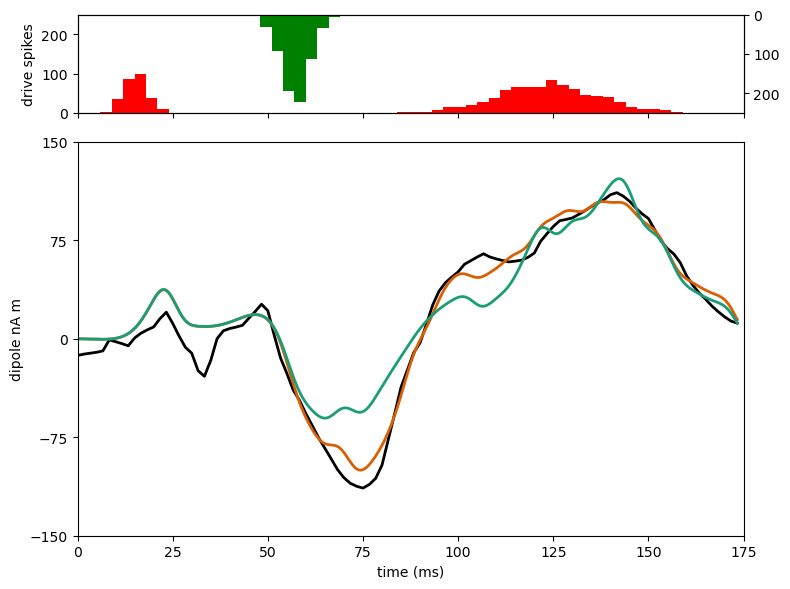

In [ ]:
fig, ax = plt.subplots(2,1,figsize=(8,6), height_ratios=[0.25, 1], sharex=True)

ax[0].hist(spike_prox1, bins, color='r')
ax[0].set_ylim([0, 250])
ax[0].set_ylabel('drive spikes')
ax[0].hist(spike_prox2, bins, color='r')

ax1tw = ax[0].twinx()
ax1tw.hist(spike_dist, bins, color='g')
ax1tw.set_ylim([0, 250])
ax1tw.invert_yaxis()

# ERP dipole
ax[1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment', color='k', linewidth=2)

ax[1].set_ylabel('dipole nA m')
ax[1].plot(avg_dpl.times,avg_dpl.data['agg'], label='optimized dipole', color=col_lines[1], linewidth=2)

ax[1].plot(avg_dpl.times,avg_dpl_no_ca.data['agg'], label='dipole Ca2+ off', color='#1b9e77', linewidth=2)

ax[1].set_ylim([-150, 150])
ax[1].set_yticks([-150, -75, 0, 75, 150])
ax[1].set_xlabel('time (ms)')
ax[1].set_xlim([0, 175])
ax[1].set_xticks(np.arange(0, 176, 25))
fig.tight_layout()
fig.savefig(op.join(pathfig, 'erp_ca_vs_no_ca.png'), dpi=600)
fig.savefig(op.join(pathfig, 'erp_ca_vs_no_ca.pdf'))

In [ ]:
net.gid_ranges

OrderedDict([('L2_inhibitory', range(0, 35)),
             ('L2_pyramidal', range(35, 135)),
             ('L5_inhibitory', range(135, 170)),
             ('L5_pyramidal', range(170, 270)),
             ('prox1', range(270, 540)),
             ('prox2', range(540, 810)),
             ('dist1', range(810, 1045))])

In [ ]:
x = range(135, 170)
type(x)


range

In [ ]:
ax

array([<Axes: ylabel='drive spikes'>,
       <Axes: xlabel='time (ms)', ylabel='dipole nA m'>], dtype=object)

In [ ]:
ax[0]

<Axes: ylabel='drive spikes'>

In [ ]:
axax = ax[0]

In [ ]:
type(ax) is np.ndarray

True

In [ ]:
import matplotlib
type(axax) is matplotlib.axes._axes.Axes

True

In [ ]:
ax